# Robustness Analysis

Evaluate model behavior under input perturbations.

In [35]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF

from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score)


In [36]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE = 32
NUM_CLASSES = 2

CLASS_NAMES = ["HP", "SSA"]

CONDITIONS = ["clean","brightness","gaussian_noise","blur"]

print("Device:", device)
print("CUDA available:", torch.cuda.is_available())
print("Conditions:", CONDITIONS)

Device: cuda
CUDA available: True
Conditions: ['clean', 'brightness', 'gaussian_noise', 'blur']


In [37]:
import os
import pandas as pd
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset

test_df = pd.read_csv("../data/metadata/test_split.csv")
images_path = os.path.abspath("../data/raw/images/images")
val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class MHISTDataset(Dataset):

    def __init__(self, dataframe, images_path, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.images_path = images_path
        self.transform = transform

        # Convert class names into numbers
        self.label_map = {
            "HP": 0,
            "SSA": 1
        }

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        # Get image name and label
        image_name = self.dataframe.loc[index, "Image Name"]
        label_name = self.dataframe.loc[index, "Majority Vote Label"]

        # Create full image path
        image_path = os.path.join(self.images_path, image_name)

        # Open image
        image = Image.open(image_path).convert("RGB")

        # Apply preprocessing/augmentation
        if self.transform:
            image = self.transform(image)

        # Convert label to number
        label = self.label_map[label_name]

        return image, label

print("MHISTDataset class created successfully!")
test_dataset = MHISTDataset(
    test_df,
    images_path,
    transform=val_test_transform
)
print("Test dataset samples:", len(test_dataset))


test_labels = [int(test_dataset[i][1]) for i in range(len(test_dataset))]

print("HP images:", test_labels.count(0))
print("SSA images:", test_labels.count(1))
print("Unique labels:", sorted(set(test_labels)))

MHISTDataset class created successfully!
Test dataset samples: 977
HP images: 617
SSA images: 360
Unique labels: [0, 1]


In [38]:
def create_model(model_name, num_classes=NUM_CLASSES, device=device):
    if model_name == "ResNet18":
        from torchvision.models import resnet18
        model = resnet18(weights=None)
        model.fc = torch.nn.Linear(model.fc.in_features, num_classes)
    elif model_name == "EfficientNet-B0":
        from torchvision.models import efficientnet_b0
        model = efficientnet_b0(weights=None)
        model.classifier[1] = torch.nn.Linear(
            model.classifier[1].in_features, num_classes
        )
    elif model_name == "MobileNetV3-Small":
        from torchvision.models import mobilenet_v3_small
        model = mobilenet_v3_small(weights=None)
        model.classifier[3] = torch.nn.Linear(
            model.classifier[3].in_features, num_classes
        )
    elif model_name == "ShuffleNetV2-x0.5":
        from torchvision.models import shufflenet_v2_x0_5
        model = shufflenet_v2_x0_5(weights=None)
        model.fc = torch.nn.Linear(model.fc.in_features, num_classes)
    else:
        raise ValueError(f"Model {model_name} not supported.")
    
    return model.to(device)

In [39]:
from torchvision.models import resnet18
from torchvision.models import efficientnet_b0
from torchvision.models import mobilenet_v3_small
from torchvision.models import shufflenet_v2_x0_5

CHECKPOINT_PATHS = {
    "ResNet18": "../models/checkpoints/resnet18.pth",
    "EfficientNet-B0": "../models/checkpoints/efficientnet_b0.pth",
    "MobileNetV3-Small": "../models/checkpoints/mobilenet_v3_small.pth",
    "ShuffleNetV2-x0.5": "../models/checkpoints/shufflenet_v3_small.pth"
}
def load_checkpoint(model, checkpoint_path):

    if not os.path.isfile(checkpoint_path):
        raise FileNotFoundError(
            f"Checkpoint not found: {checkpoint_path}"
        )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    # Support common checkpoint formats
    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]

    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]

    else:
        state_dict = checkpoint

    # Handle weights saved from DataParallel
    state_dict = {
        key.removeprefix("module."): value
        for key, value in state_dict.items()
    }

    model.load_state_dict(state_dict)
    model = model.to(device)
    model.eval()

    return model
model_names = []
trained_models = {}
missing_checkpoints = []

for name, path in CHECKPOINT_PATHS.items():
    if not os.path.isfile(path):
        missing_checkpoints.append((name, path))
        print(f"Skipping {name}: checkpoint not found at {path}")
        continue

    model = create_model(name, num_classes=NUM_CLASSES, device=device)
    trained_models[name] = load_checkpoint(model, path)
    model_names.append(name)

    print("Loaded:", name)

if missing_checkpoints:
    print("\nTo include the baseline models, run the ResNet18 and EfficientNet-B0 training cells in 03_baseline.ipynb first.")
    print("Those cells save the required checkpoints under ../models/checkpoints/.")

Loaded: ResNet18
Loaded: EfficientNet-B0
Loaded: MobileNetV3-Small
Loaded: ShuffleNetV2-x0.5


In [40]:
class RobustnessDataset(Dataset):
    def __init__(self,original_dataset,condition):
        self.original_dataset=original_dataset
        self.condition=condition
        self.mean=torch.sensor([0.485,0.456,0.406].view(3,1,1))
        self.std=torch.tensor([0.229,0.224,0.225]).view(3,1,1)
    def __len__(self):
        return len(self.original_dataset)
    def __getitem__(self, index):
        image,label=self.original_dataset[index]
        if self.condition=="clean":
            return image,label
        if self.condition=="brightness":
            image=TF.adjust_brightness(image,0.7)
        elif self.condition=="gaussian_noise":
            generator=torch.Generator()
            generator.manual_seed(12345+index)
            noise=torch.randn(image.shape,generator=generator)*0.05
            image=(image+noise).clamp(0,1)
        elif self.condition=="blur":
            image=TF.gaussian_blur(image,kernel_size=[5,5],sigma=[1,1])
            image=(image-self.mean)/self.std
            return image,label

        

In [41]:
class RobustnessDataset(Dataset):
    def __init__(self, original_dataset, condition):
        self.original_dataset = original_dataset
        self.condition = condition
        self.mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        self.std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    def __len__(self):
        return len(self.original_dataset)

    def __getitem__(self, index):
        image, label = self.original_dataset[index]

        if self.condition == "clean":
            return image, label

        image = (image * self.std + self.mean).clamp(0, 1)

        if self.condition == "brightness":
            image = TF.adjust_brightness(image, 0.7)
        elif self.condition == "gaussian_noise":
            generator = torch.Generator()
            generator.manual_seed(12345 + index)
            noise = torch.randn(image.shape, generator=generator) * 0.05
            image = (image + noise).clamp(0, 1)
        elif self.condition == "blur":
            image = TF.gaussian_blur(image, kernel_size=[5, 5], sigma=[1, 1])
        else:
            raise ValueError(f"Unknown condition: {self.condition}")

        image = (image - self.mean) / self.std
        return image, label


def evaluate_model(model, dataset, condition):
    perturbed_dataset = RobustnessDataset(dataset, condition)
    loader = DataLoader(perturbed_dataset, batch_size=BATCH_SIZE, shuffle=False)
    all_labels = []
    all_predictions = []
    all_probabilities = []
    model.eval()

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            probabilities = torch.softmax(outputs, dim=1)
            predictions = torch.argmax(outputs, dim=1)
            all_labels.extend(labels.numpy())
            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities[:, 1].cpu().numpy())

    accuracy = accuracy_score(all_labels, all_predictions)
    precision = precision_score(all_labels, all_predictions, pos_label=1, zero_division=0)
    ssa_recall = recall_score(all_labels, all_predictions, pos_label=1, zero_division=0)
    f1 = f1_score(all_labels, all_predictions, pos_label=1, zero_division=0)
    macro_f1 = f1_score(all_labels, all_predictions, average="macro", zero_division=0)

    try:
        roc_auc = roc_auc_score(all_labels, all_probabilities)
    except ValueError:
        roc_auc = np.nan

    hp_recall = recall_score(all_labels, all_predictions, pos_label=0, zero_division=0)

    return {
        "Accuracy": accuracy,
        "Precision (SSA)": precision,
        "SSA Recall": ssa_recall,
        "HP Recall": hp_recall,
        "F1 (SSA)": f1,
        "Macro F1": macro_f1,
        "ROC-AUC": roc_auc
    }


all_results = []
for model_name, model in trained_models.items():
    for condition in CONDITIONS:
        print(f"Evaluating {model_name} | {condition}")
        scores = evaluate_model(model, test_dataset, condition)
        row = {"Model": model_name, "Condition": condition, **scores}
        all_results.append(row)

results_df = pd.DataFrame(all_results)
print(results_df.round(4).to_string(index=False))

Evaluating ResNet18 | clean
Evaluating ResNet18 | brightness
Evaluating ResNet18 | gaussian_noise
Evaluating ResNet18 | blur
Evaluating EfficientNet-B0 | clean
Evaluating EfficientNet-B0 | brightness
Evaluating EfficientNet-B0 | gaussian_noise
Evaluating EfficientNet-B0 | blur
Evaluating MobileNetV3-Small | clean
Evaluating MobileNetV3-Small | brightness
Evaluating MobileNetV3-Small | gaussian_noise
Evaluating MobileNetV3-Small | blur
Evaluating ShuffleNetV2-x0.5 | clean
Evaluating ShuffleNetV2-x0.5 | brightness
Evaluating ShuffleNetV2-x0.5 | gaussian_noise
Evaluating ShuffleNetV2-x0.5 | blur
            Model      Condition  Accuracy  Precision (SSA)  SSA Recall  HP Recall  F1 (SSA)  Macro F1  ROC-AUC
         ResNet18          clean    0.4831           0.3847      0.6722     0.3728    0.4894    0.4830   0.5435
         ResNet18     brightness    0.4493           0.3652      0.6694     0.3209    0.4725    0.4483   0.4734
         ResNet18 gaussian_noise    0.5200           0.4125     

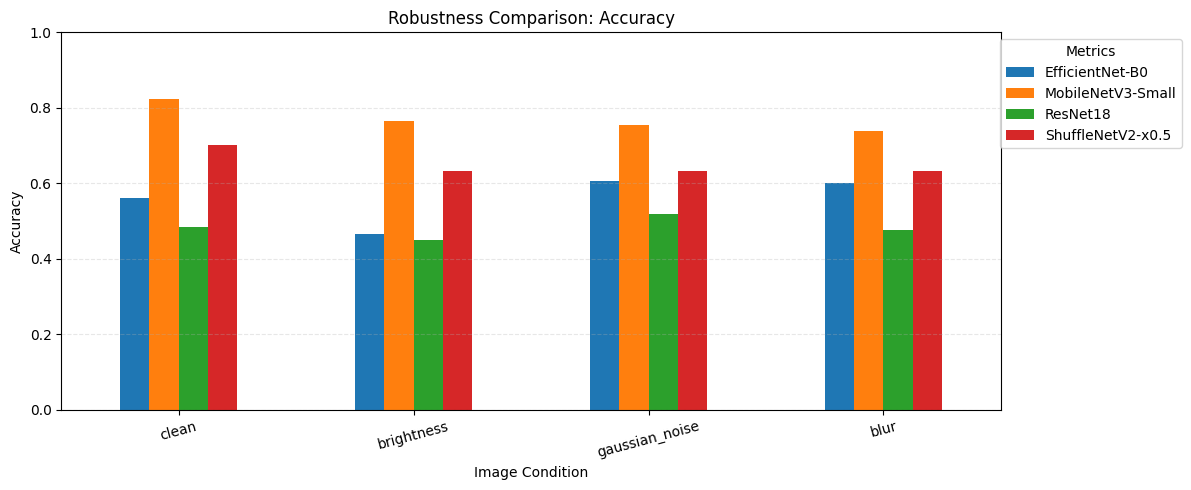

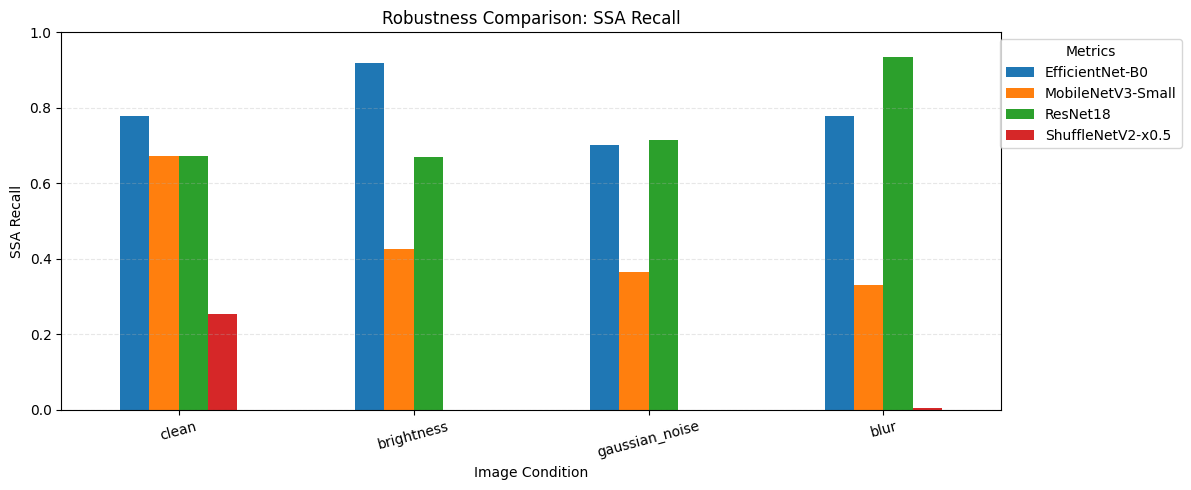

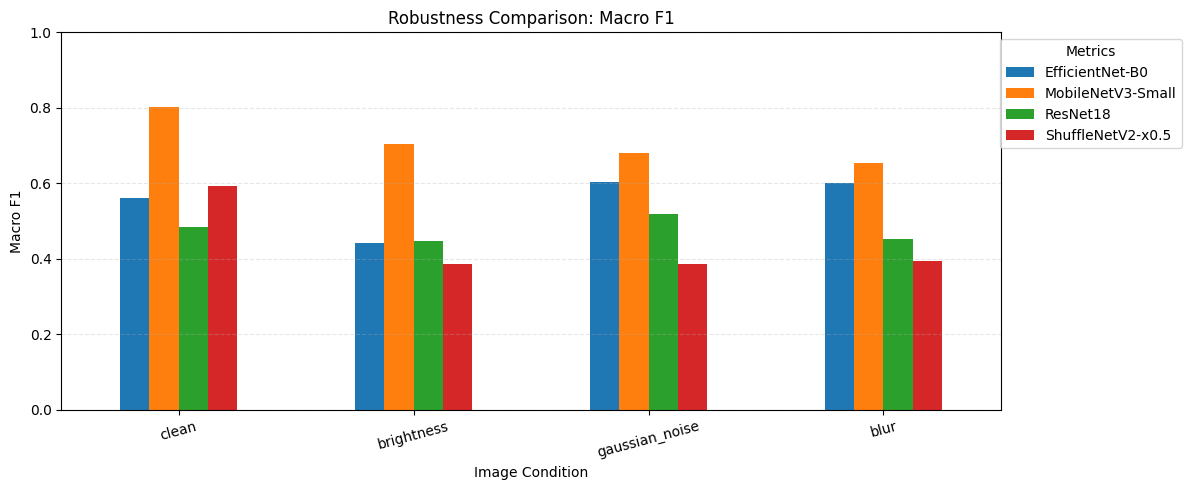

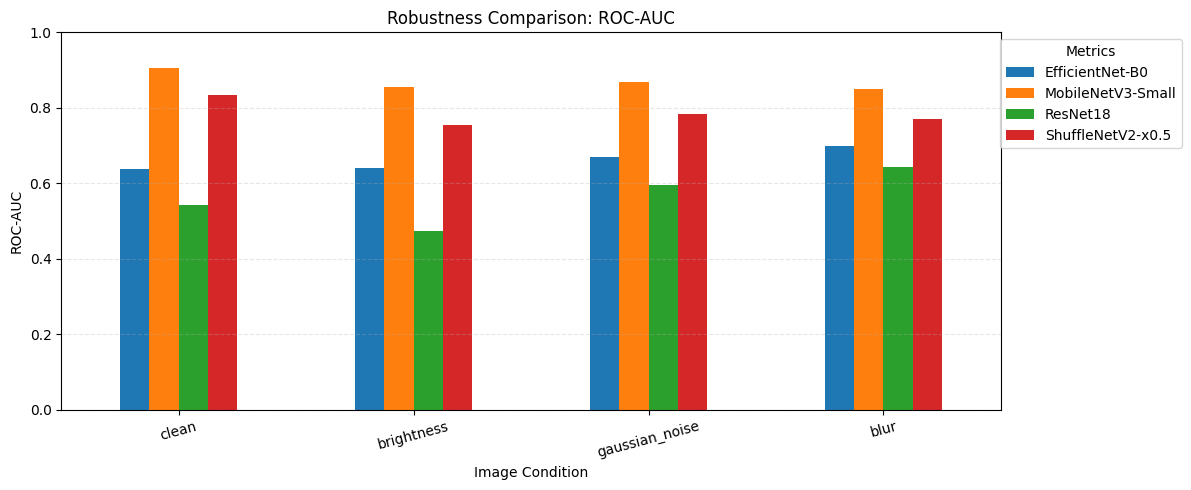

In [45]:
metrics_to_plot = ["Accuracy","SSA Recall","Macro F1","ROC-AUC"]

for metric in metrics_to_plot:
    pivot_df = results_df.pivot(index="Condition",columns="Model",values=metric)
    pivot_df = pivot_df.reindex(CONDITIONS)
    pivot_df.plot(kind="bar",figsize=(12, 5))

    plt.title(f"Robustness Comparison: {metric}")
    plt.xlabel("Image Condition")
    plt.ylabel(metric)
    plt.ylim(0, 1)
    plt.xticks(rotation=15)
    plt.legend(title="Model")
    plt.grid(axis="y", linestyle="--", alpha=0.3)
    plt.legend(title="Metrics", loc="upper right", bbox_to_anchor=(1.2, 1))
    plt.tight_layout()
    plt.savefig(f"../results/figures/robustness_{metric.lower().replace(' ', '_')}.png", dpi=300, bbox_inches="tight")
    plt.show()

In [43]:
metrics_for_drop = [
    "Accuracy",
    "SSA Recall",
    "Macro F1",
    "ROC-AUC"
]

drop_results = []

for model_name in results_df["Model"].unique():

    model_data = results_df[
        results_df["Model"] == model_name
    ].set_index("Condition")

    clean_scores = model_data.loc["clean"]

    for condition in CONDITIONS:

        current_scores = model_data.loc[condition]

        row = {
            "Model": model_name,
            "Condition": condition
        }

        for metric in metrics_for_drop:

            # Positive values indicate a performance drop
            drop = clean_scores[metric] - current_scores[metric]

            row[f"{metric} Drop (pp)"] = drop * 100

        drop_results.append(row)

drop_df = pd.DataFrame(drop_results)

print(drop_df.round(2).to_string(index=False))

            Model      Condition  Accuracy Drop (pp)  SSA Recall Drop (pp)  Macro F1 Drop (pp)  ROC-AUC Drop (pp)
         ResNet18          clean                0.00                  0.00                0.00               0.00
         ResNet18     brightness                3.38                  0.28                3.48               7.01
         ResNet18 gaussian_noise               -3.68                 -4.17               -3.69              -5.24
         ResNet18           blur                0.61                -26.11                3.04              -9.86
  EfficientNet-B0          clean                0.00                  0.00                0.00               0.00
  EfficientNet-B0     brightness                9.62                -14.17               12.13              -0.33
  EfficientNet-B0 gaussian_noise               -4.40                  7.50               -4.10              -3.21
  EfficientNet-B0           blur               -3.99                  0.00              

In [ ]:
import os
os.makedirs("../results/tables", exist_ok=True)

results_df.to_csv("../results/tables/robustness_all_models.csv",index=False)
drop_df.to_csv("../results/tables/robustness_performance_drops.csv",index=False)
print("Saved both robustness result tables.")